# 01 · Exploratory data analysis

What the NER and secret-detector training data looks like after the pipeline in
`src/promptshield/data/` (ingest → label unification → synthetic data → cleaning →
validation → grouped split).

In [1]:
import json
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

In [2]:
ner = pd.read_parquet(ROOT / "data/processed/ner.parquet")
sec = pd.read_parquet(ROOT / "data/processed/secrets.parquet")
report = json.loads((ROOT / "reports/data_quality.json").read_text())
print(f"NER rows: {len(ner):,}   secret texts: {len(sec):,}")
pd.crosstab(ner["source"], ner["split"], margins=True)

NER rows: 68,807   secret texts: 38,227


split,test,train,val,All
source,,,,
ai4privacy,8415,39273,8415,56103
synth,1860,10196,648,12704
All,10275,49469,9063,68807


## Entity label distribution (unified labels)

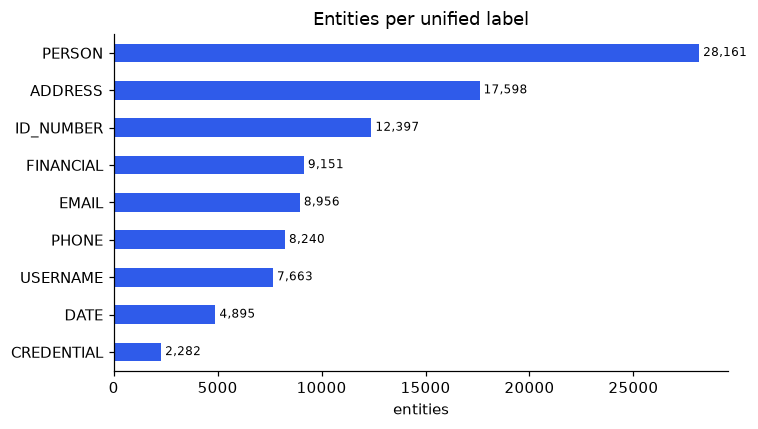

In [3]:
counts = Counter(s["label"] for spans in ner["spans"] for s in spans)
s = pd.Series(counts).sort_values()
ax = s.plot.barh(color="#2f5bea", figsize=(7, 4))
ax.set_xlabel("entities"); ax.set_title("Entities per unified label")
for i, v in enumerate(s.values):
    ax.text(v, i, f" {v:,}", va="center", fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "entity_distribution.png"); plt.show()

CREDENTIAL and DATE are the rarest labels, which is why the PyTorch loss uses softened inverse-frequency class weights.

## Text length and entity density by source

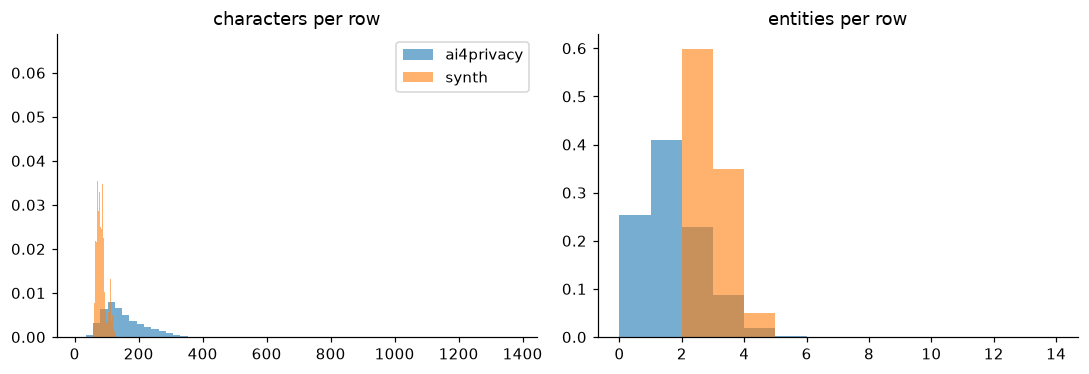

chars                                                  \
              count   mean   std   min    25%    50%    75%     max   
source                                                                
ai4privacy  56103.0  152.8  65.5  12.0  104.0  138.0  190.0  1377.0   
synth       12704.0   82.9  14.2  50.0   74.0   80.0   88.0   133.0   

           n_entities                                     
                count mean  std  min  25%  50%  75%  max  
source                                                    
ai4privacy    56103.0  1.2  1.0  0.0  0.0  1.0  2.0  8.0  
synth         12704.0  2.4  0.6  0.0  2.0  2.0  3.0  4.0

In [4]:
ner["chars"] = ner["text"].str.len()
ner["n_entities"] = ner["spans"].str.len()
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for src, g in ner.groupby("source"):
    axes[0].hist(g["chars"], bins=60, alpha=0.6, label=src, density=True)
    axes[1].hist(g["n_entities"], bins=range(0, 15), alpha=0.6, label=src, density=True)
axes[0].set_title("characters per row"); axes[1].set_title("entities per row")
axes[0].legend(); plt.tight_layout(); plt.savefig(FIG / "lengths.png"); plt.show()
ner.groupby("source")[["chars", "n_entities"]].describe().round(1)

## Data quality report

Generated by `data/build.py`; pandera schema and leakage checks passed before this file was written.

In [5]:
{k: v for k, v in report.items() if k not in ("entity_counts", "text_len_chars")}

{'rows': 68807,
 'by_source': {'ai4privacy': 56103, 'synth': 12704},
 'by_split': {'train': 49469, 'test': 10275, 'val': 9063},
 'rows_without_entities': 14250,
 'n_templates': 56115,
 'unmapped_source_labels': {},
 'dropped_unlabeled_rows_with_identifiers': 3896,
 'secrets': {'rows': 38752,
  'positive_rate': 0.463,
  'by_split': {'train': 27238, 'test': 6217, 'val': 5297}}}

## Secret-detector data

Positives are fake credentials in real formats; negatives are look-alikes (hashes, UUIDs, placeholders, env-var names, IDs).

In [6]:
sec["kind_group"] = np.where(sec["label"] == 1, "secret", "look-alike")
print(sec["label"].value_counts(normalize=True).round(3))
sec.groupby(["split", "kind_group"]).size().unstack()

label
0    0.526
1    0.474
Name: proportion, dtype: float64


kind_group,look-alike,secret
split,,
test,3019,2716
train,14087,12671
val,3018,2716
